# Tree pollen grain classification with a CNN

**Question:** can a small CNN identify tree pollen species from cropped microscope images?

**Data:** POLLEN20L-det (Kaggle). `bboxes.csv` has one row per grain: `image, x1, y1, x2, y2, label`, with **no header row**. The notebook crops each grain out of its photo, so every grain becomes one small image.

**Two design choices worth stating in the report**
- **Split by original photo, not by grain.** The file names look like Roboflow exports (`<photo>.rf.<hash>.jpg`), and the same photo can appear several times as augmented copies. Splitting randomly could put near-identical copies in both train and test and inflate accuracy.
- **Report per-class F1, not just accuracy.** Classes are imbalanced (maple has about 1,150 grains, pine about 230).

**Folder layout this notebook expects** (change the paths in the config cell if yours differ):
```
bboxes.csv
images/   <- every file named in bboxes.csv
pollen_cnn.ipynb
```

## 1. Setup

In [3]:
# If keras is missing, run this in its own cell, then restart the kernel:
# %pip install keras tensorflow

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from sklearn.metrics import classification_report, confusion_matrix, f1_score

In [4]:
import os
print(os.getcwd())
print(os.path.exists("data/bboxes.csv"), os.path.exists("../data/bboxes.csv"))

/Users/saariyafaraz/Desktop/DS4420_Proj1/scripts
False True


In [5]:
CSV_PATH  = "../data/bboxes.csv"
IMAGE_DIR = "../data/images"

In [6]:
# Tree classes only. Hazel is left out (77 grains is too few).
CLASSES = ["maple", "willow", "birch", "alder", "linden", "pine"]

# each grain is padded to a square and resized to IMG_SIZE x IMG_SIZE
IMG_SIZE = 64
# skip boxes with a side shorter than this many pixels
MIN_SIDE = 10     
SEED     = 42

## 2. Load the annotations

In [8]:
cols = ["image", "x1", "y1", "x2", "y2", "label"]

# Missing header row in the file
df = pd.read_csv(CSV_PATH, header=None, names=cols)

# Original photo = file name before ".rf."  (augmented copies share this prefix)
df["source"] = df["image"].str.split(".rf.", n=1, regex=False).str[0]

print("all grains:", df.shape[0])
print("image files:", df["image"].nunique(), "| original photos:", df["source"].nunique())
print()
print(df["label"].value_counts().to_string())

all grains: 7744
image files: 2412 | original photos: 1787

label
maple              1159
willow              816
birch               666
hill_mustard        660
angelica            472
alder               470
fireweed            366
angelica_garden     354
linden              339
clover              320
pigweed             317
sorrel              271
meadow_pink         235
nettle              231
pine                230
plantain            217
grass               213
buckwheat           213
mugwort             118
hazel                77


In [9]:
# Keep only the chosen classes and drop very small boxes
df = df[df["label"].isin(CLASSES)].copy()
w = df["x2"] - df["x1"]
h = df["y2"] - df["y1"]
small = (w < MIN_SIDE) | (h < MIN_SIDE)
print("dropping", int(small.sum()), "boxes smaller than", MIN_SIDE, "px")
df = df[~small].reset_index(drop=True)

class_to_id = {c: i for i, c in enumerate(CLASSES)}
print(class_to_id)
print(df["label"].value_counts().to_string())

dropping 0 boxes smaller than 10 px
{'maple': 0, 'willow': 1, 'birch': 2, 'alder': 3, 'linden': 4, 'pine': 5}
label
maple     1159
willow     816
birch      666
alder      470
linden     339
pine       230


## 3. Crop each grain



In [11]:
# Each box is cropped, padded to a square (so grains aren't stretched), and resized. Images are stored as `uint8`; the model rescales them to 0-1 itself.

X, keep, missing = [], [], set()

for fname, g in df.groupby("image"):
    path = os.path.join(IMAGE_DIR, fname)
    if not os.path.exists(path):
        missing.add(fname)
        continue
    with Image.open(path) as im:
        im = im.convert("RGB")
        W, H = im.size
        for idx, r in g.iterrows():
            box = (max(int(r.x1), 0), max(int(r.y1), 0), min(int(r.x2), W), min(int(r.y2), H))
            if box[2] - box[0] < 2 or box[3] - box[1] < 2:
                continue
            crop = ImageOps.pad(im.crop(box), (IMG_SIZE, IMG_SIZE), color=(0, 0, 0))
            X.append(np.asarray(crop))
            keep.append(idx)

if missing:
    print("WARNING:", len(missing), "image files listed in the CSV were not found in", IMAGE_DIR)
    print("first few:", list(missing)[:3])

df = df.loc[keep].reset_index(drop=True)
X = np.stack(X)
y = df["label"].map(class_to_id).to_numpy()
print("crops:", X.shape, X.dtype, "| labels:", y.shape)

crops: (3680, 64, 64, 3) uint8 | labels: (3680,)


## 4. Split by original photo (70% / 15% / 15%)

In [13]:
rng = np.random.default_rng(SEED)
sources = df["source"].unique()
rng.shuffle(sources)

n = len(sources)
train_src = set(sources[: int(0.70 * n)])
val_src   = set(sources[int(0.70 * n): int(0.85 * n)])

split = np.where(df["source"].isin(train_src), "train",
        np.where(df["source"].isin(val_src), "val", "test"))

# no photo may appear in more than one split
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    assert not (set(df.loc[split == a, "source"]) & set(df.loc[split == b, "source"])), (a, b)

X_train, y_train = X[split == "train"], y[split == "train"]
X_val,   y_val   = X[split == "val"],   y[split == "val"]
X_test,  y_test  = X[split == "test"],  y[split == "test"]

print(pd.crosstab(df["label"], split)[["train", "val", "test"]])

col_0   train  val  test
label                   
alder     352   63    55
birch     501   37   128
linden    236   59    44
maple     873  168   118
pine      162   40    28
willow    561  144   111


In [14]:
# Class weights so rarer species count more during training
counts = np.bincount(y_train, minlength=len(CLASSES))
class_weight = {i: len(y_train) / (len(CLASSES) * c) for i, c in enumerate(counts) if c > 0}
print({CLASSES[i]: round(float(w), 2) for i, w in class_weight.items()})

{'maple': 0.51, 'willow': 0.8, 'birch': 0.89, 'alder': 1.27, 'linden': 1.9, 'pine': 2.76}


## 5. Look at some crops (a good poster figure)

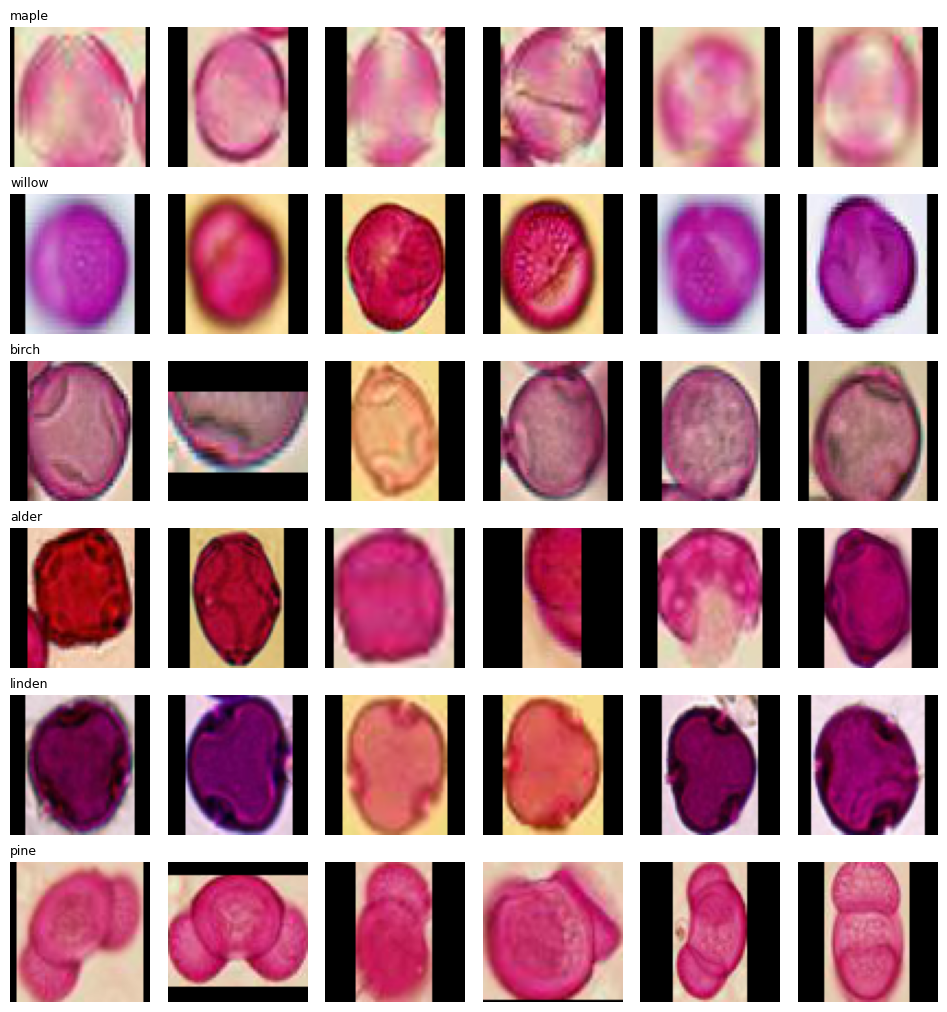

In [16]:
per_class = 6
fig, axes = plt.subplots(len(CLASSES), per_class, figsize=(per_class * 1.6, len(CLASSES) * 1.7))
for r, name in enumerate(CLASSES):
    idxs = np.where(y == class_to_id[name])[0]
    pick = rng.choice(idxs, size=min(per_class, len(idxs)), replace=False)
    for c in range(per_class):
        ax = axes[r, c]
        ax.axis("off")
        if c < len(pick):
            ax.imshow(X[pick[c]])
        if c == 0:
            ax.set_title(name, loc="left", fontsize=9)
plt.tight_layout()
plt.show()

## 6. Build and train the CNN

Three small conv blocks, then a dense layer with dropout. Random flips and rotations act as augmentation (pollen grains have no fixed orientation) and are only active during training.

In [18]:
import keras
from keras import layers

keras.utils.set_random_seed(SEED)

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = layers.Rescaling(1.0 / 255)(inputs)
x = layers.RandomFlip("horizontal_and_vertical")(x)
x = layers.RandomRotation(0.2)(x)

for filters in (16, 32, 64):
    x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)

x = layers.Flatten()(x)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(len(CLASSES), activation="softmax")(x)

model = keras.Model(inputs, outputs)
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 64, 64, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 286,182 (1.09 MB)

 Trainable params: 286,182 (1.09 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=40, batch_size=32,
    class_weight=class_weight,
    callbacks=[early_stop],
)

Epoch 1/40
84/84 ━━━━━━━━━━━━━━━━━━━━ 14s 130ms/step - accuracy: 0.2883 - loss: 1.6421 - val_accuracy: 0.6262 - val_loss: 1.2279
Epoch 2/40
84/84 ━━━━━━━━━━━━━━━━━━━━ 6s 69ms/step - accuracy: 0.4600 - loss: 1.3605 - val_accuracy: 0.7534 - val_loss: 0.9787
Epoch 3/40
84/84 ━━━━━━━━━━━━━━━━━━━━ 7s 81ms/step - accuracy: 0.5456 - loss: 1.1547 - val_accuracy: 0.8102 - val_loss: 0.6591
Epoch 4/40
84/84 ━━━━━━━━━━━━━━━━━━━━ 7s 85ms/step - accuracy: 0.5933 - loss: 0.9961 - val_accuracy: 0.8141 - val_loss: 0.5894
Epoch 5/40
84/84 ━━━━━━━━━━━━━━━━━━━━ 4s 54ms/step - accuracy: 0.6883 - loss: 0.8251 - val_accuracy: 0.8924 - val_loss: 0.3985
Epoch 6/40
84/84 ━━━━━━━━━━━━━━━━━━━━ 46s 552ms/step - accuracy: 0.7497 - loss: 0.7001 - val_accuracy: 0.8748 - val_loss: 0.4322
Epoch 7/40
84/84 ━━━━━━━━━━━━━━━━━━━━ 12s 147ms/step - accuracy: 0.7810 - loss: 0.5891 - val_accuracy: 0.8982 - val_loss: 0.2843
Epoch 8/40
84/84 ━━━━━━━━━━━━━━━━━━━━ 6s 75ms/step - accuracy: 0.8130 - loss: 0.5275 - val_accuracy: 0.92

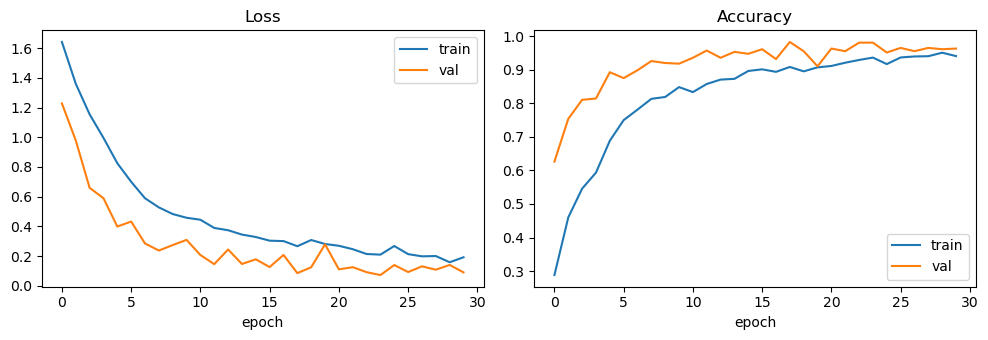

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(history.history["loss"], label="train")
ax[0].plot(history.history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train")
ax[1].plot(history.history["val_accuracy"], label="val")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout()
plt.show()

## 7. Evaluate on the held-out test photos

Compare against the baseline of always predicting the most common training class. Per-class precision, recall and F1 matter more than overall accuracy here.

In [22]:
probs = model.predict(X_test, verbose=0)
y_pred = probs.argmax(axis=1)

baseline = np.mean(y_test == np.bincount(y_train).argmax())
print(f"test accuracy:            {np.mean(y_pred == y_test):.3f}")
print(f"majority-class baseline:  {baseline:.3f}")
print(f"macro F1:                 {f1_score(y_test, y_pred, average='macro', zero_division=0):.3f}")
print()
print(classification_report(y_test, y_pred, labels=range(len(CLASSES)),
                            target_names=CLASSES, zero_division=0))

test accuracy:            0.981
majority-class baseline:  0.244
macro F1:                 0.976

              precision    recall  f1-score   support

       maple       0.99      0.99      0.99       118
      willow       1.00      0.95      0.98       111
       birch       1.00      1.00      1.00       128
       alder       0.88      0.96      0.92        55
      linden       1.00      1.00      1.00        44
        pine       0.96      0.96      0.96        28

    accuracy                           0.98       484
   macro avg       0.97      0.98      0.98       484
weighted avg       0.98      0.98      0.98       484



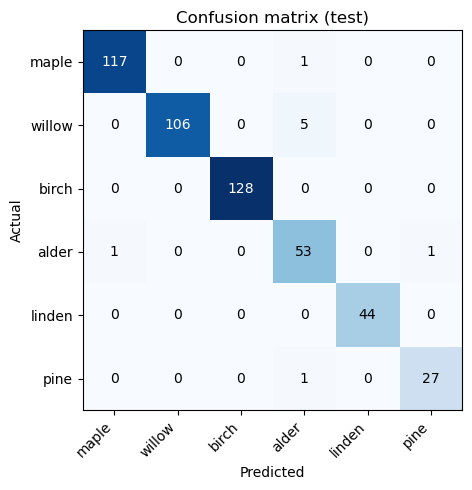

In [24]:
cm = confusion_matrix(y_test, y_pred, labels=range(len(CLASSES)))
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES, rotation=45, ha="right")
ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title("Confusion matrix (test)")
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

In [28]:
# saving model to avoid retraining
model.save("pollen_cnn.keras")